# 4. Die ausgewählten Modelle verstehen und anwenden

Wir erklären die beste logistische Regression, den besten Entscheidungsbaum und das beste KNN-Modell aus [Notebook 3](03_Modellvergleich.ipynb).

Zuerst vergleichen wir ihre Vorhersagen für die 179 Kontrollpersonen. Anschließend lernen dieselben Modelle mit allen 891 Personen mit bekanntem Überleben und sagen das Ergebnis für die 418 Testpersonen voraus. Die Auswahl aus Notebook 3 bleibt bestehen.


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def style_leaf_tree(annotations):
    cream = to_rgb(COLORS['lt2'])
    for annotation in annotations:
        text = annotation.get_text()
        color = COLORS['accent3'] if 'class = Überlebt' in text else COLORS['accent1'] if 'class = Nicht überlebt' in text else COLORS['accent2']
        annotation.set_color(COLORS['dk2'])
        bbox = annotation.get_bbox_patch()
        if bbox is not None:
            tint = tuple((0.14 * c + 0.86 * b for c, b in zip(to_rgb(color), cream)))
            bbox.set_facecolor(tint)
            bbox.set_edgecolor(color)
            bbox.set_linewidth(0.9)
        if annotation.arrow_patch is not None:
            annotation.arrow_patch.set_color(COLORS['accent2'])

def plot_leaf_tree_horizontal(estimator, feature_names, *, figsize=(16, 9)):
    tree = estimator.tree_
    spacing = 1.18

    def layout(node):
        if tree.children_left[node] == -1:
            return {node: (0, 0.0)}
        left = layout(tree.children_left[node])
        right = layout(tree.children_right[node])
        shared = {d for d, _ in left.values()} & {d for d, _ in right.values()}
        gap = max((max((y for d, y in left.values() if d == level)) - min((y for d, y in right.values() if d == level)) + spacing for level in shared))
        points = {node: (0, 0.0)}
        points.update({n: (d + 1, y - gap / 2) for n, (d, y) in left.items()})
        points.update({n: (d + 1, y + gap / 2) for n, (d, y) in right.items()})
        return points
    positions = layout(0)
    assert len(positions) == tree.node_count
    depth = estimator.get_depth()
    aliases = {'Age': 'Alter', 'Fare': 'Fahrpreis', 'SibSp': 'Geschw./Partner', 'Sex_male': 'Männlich', 'Pclass_3': 'Klasse 3', 'Familiengruppe_5+': 'Familie 5+', 'ErwachsenerKinderticket': 'Kinderticket', 'Kabinenposition_Unklar': 'Position unklar', 'Kabinendeck_D': 'Deck D', 'Kabinenlage_E-Front': 'Lage E-Front', 'Embarked_S': 'Einstieg S'}
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_axis_off()
    cream = to_rgb(COLORS['lt2'])
    box_width, box_height = (0.8, 1.02)
    min_y = min((y for _, y in positions.values()))
    max_y = max((y for _, y in positions.values()))
    ax.set_xlim(-0.5, depth + 0.5)
    ax.set_ylim(max_y + 0.75, min_y - 1.15)
    for level in range(depth + 1):
        ax.text(level, min_y - 0.9, 'Start' if level == 0 else f'Ebene {level}', ha='center', va='center', fontsize=9, color=COLORS['accent2'])
    for node, (level, y) in positions.items():
        if tree.children_left[node] != -1:
            for child in [tree.children_left[node], tree.children_right[node]]:
                child_level, child_y = positions[child]
                ax.add_patch(FancyArrowPatch((level + box_width / 2, y), (child_level - box_width / 2, child_y), arrowstyle='->', mutation_scale=5, linewidth=0.65, color=COLORS['accent2'], zorder=1))
                if node == 0:
                    ax.text(level + 0.5, (y + child_y) / 2, 'Ja' if child == tree.children_left[node] else 'Nein', fontsize=8, ha='center', color=COLORS['dk2'], bbox={'facecolor': COLORS['lt2'], 'edgecolor': 'none', 'pad': 1})
    labels = []
    for node, (level, y) in positions.items():
        values = tree.value[node].reshape(-1)
        survival = values[1] / values.sum()
        prediction = int(values.argmax())
        leaf = tree.children_left[node] == -1
        color = COLORS['accent3'] if prediction else COLORS['accent1']
        tint = tuple((0.14 * c + 0.86 * b for c, b in zip(to_rgb(color), cream)))
        ax.add_patch(FancyBboxPatch((level - box_width / 2, y - box_height / 2), box_width, box_height, boxstyle='round,pad=0.015,rounding_size=0.04', facecolor=tint, edgecolor=color, linewidth=0.85 if leaf else 0.65, zorder=2))
        if leaf:
            condition = 'Überlebt' if prediction else 'Nicht überlebt'
        else:
            name = str(feature_names[tree.feature[node]])
            threshold = tree.threshold[node]
            if name not in ('Age', 'Fare', 'SibSp') and abs(threshold - 0.5) < 1e-08:
                condition = f'{aliases.get(name, name)} = 0?'
            else:
                condition = f'{aliases.get(name, name)} ≤ {threshold:.3g}?'
        label = f'{condition}\nn={tree.n_node_samples[node]}  ·  Ü={survival:.0%}'
        artist = ax.text(level, y, label, ha='center', va='center', fontsize=7.3, linespacing=1.2, color=COLORS['dk2'], zorder=3)
        labels.append(artist)
    fig._leaf_tree_layout = {'nodes': tree.node_count, 'leaves': estimator.get_n_leaves(), 'depth': depth, 'positions': positions, 'labels': labels}
    return (fig, ax)

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
import json
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, brier_score_loss, cohen_kappa_score
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

class FoldLocalTicketFeatures(TransformerMixin, BaseEstimator):

    def fit(self, X, y=None):
        tickets = X.Ticket.str.strip().str.upper()
        self.ticket_counts_ = tickets.value_counts()
        self.child_tickets_ = frozenset(tickets[X.Age.lt(18)].dropna())
        self.fit_passenger_ids_ = tuple(X.PassengerId) if 'PassengerId' in X else ()
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        result = X.copy()
        tickets = X.Ticket.str.strip().str.upper()
        result['ErwachsenerKinderticket'] = (X.Age.ge(18) & tickets.isin(self.child_tickets_)).astype(int)
        counts = tickets.map(self.ticket_counts_).fillna(1).clip(lower=1)
        result['LogFahrpreisProPerson'] = np.log1p(X.Fare / counts)
        return result
MODEL_TYPES = {'Logistic Regression': LogisticRegression(max_iter=2000), 'Shallow Decision Tree': DecisionTreeClassifier(random_state=42), 'Extended Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=42), 'KNN': KNeighborsClassifier(algorithm='brute', n_jobs=1)}
PARAMETER_GRIDS = {'Logistic Regression': {'C': [0.1, 1.0, 10.0]}, 'Shallow Decision Tree': {'max_depth': [2, 3], 'min_samples_leaf': [15, 30]}, 'Extended Decision Tree': {'max_depth': [4, 7], 'min_samples_leaf': [5, 15]}, 'KNN': {'n_neighbors': [5, 15, 31], 'p': [1, 2], 'weights': ['uniform', 'distance']}}
FAMILIES = {'Logistic Regression': 'Logistic Regression', 'Shallow Decision Tree': 'Decision Tree', 'Extended Decision Tree': 'Decision Tree', 'KNN': 'KNN'}
CONTINUOUS = {'Age', 'SibSp', 'Parch', 'Fare', 'LogFahrpreisProPerson'}

def preprocessing(columns):
    numeric = [name for name in columns['numerisch'] if name in CONTINUOUS]
    indicators = [name for name in columns['numerisch'] if name not in CONTINUOUS]
    blocks = [('numerisch', Pipeline([('ergänzen', SimpleImputer(strategy='median', keep_empty_features=True)), ('skalieren', StandardScaler())]), numeric), ('kategorisch', Pipeline([('ergänzen', SimpleImputer(strategy='constant', fill_value='Unbekannt', keep_empty_features=True)), ('kodieren', OneHotEncoder(drop=None, min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False))]), columns['kategorisch'])]
    if indicators:
        blocks.append(('indikatoren', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True), indicators))
    return ColumnTransformer(blocks, verbose_feature_names_out=False)

def make_pipeline(model_type, columns, parameters):
    return Pipeline([('ticketmerkmale', FoldLocalTicketFeatures()), ('vorbereitung', preprocessing(columns)), ('modell', clone(MODEL_TYPES[model_type]).set_params(**parameters))])

def metrics(y, prediction, probability):
    return {'Accuracy': accuracy_score(y, prediction), 'Precision': precision_score(y, prediction, zero_division=0), 'Recall': recall_score(y, prediction, zero_division=0), 'F1': f1_score(y, prediction, zero_division=0), 'ROC AUC': roc_auc_score(y, probability), 'Brier score': brier_score_loss(y, probability), "Cohen's kappa": cohen_kappa_score(y, prediction)}

def pipeline_from_row(row, groups):
    parameters = row['Parameter']
    if isinstance(parameters, str):
        parameters = json.loads(parameters)
    return make_pipeline(row['Modell'], groups[row['Merkmalsgruppe']], parameters)



In [3]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
pd.set_option('display.precision', 4)
ERGEBNISSE = Path('ergebnisse')
auswahl = json.loads((ERGEBNISSE / 'modell_auswahl.json').read_text(encoding='utf-8'))
daten = pd.read_csv(ERGEBNISSE / 'train_merkmale.csv')
gruppen = json.loads((ERGEBNISSE / 'merkmalsgruppen.json').read_text(encoding='utf-8'))
test = pd.read_csv(ERGEBNISSE / 'test_merkmale.csv')
raw_test = pd.read_csv('test.csv')
aufteilung = pd.read_csv(ERGEBNISSE / 'datenaufteilung.csv')
entwicklungs_ids = aufteilung.loc[aufteilung.Bereich.eq('Entwicklung'), 'PassengerId']
holdout_ids = aufteilung.loc[aufteilung.Bereich.eq('Prüfung'), 'PassengerId']
entwicklung = daten.set_index('PassengerId').loc[entwicklungs_ids].reset_index()
holdout = daten.set_index('PassengerId').loc[holdout_ids].reset_index()
X_entwicklung = entwicklung.drop(columns='Survived')
X_holdout = holdout.drop(columns='Survived')
wahrheit = holdout.Survived.to_numpy()
assert set(entwicklungs_ids).isdisjoint(holdout_ids)
assert test.PassengerId.equals(raw_test.PassengerId)
OUTPUT, FIGURES = (ERGEBNISSE / '04_top3', Path('abbildungen/04_top3'))
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
apply_leaf_theme()
top3 = auswahl['Top3']
assert len(top3) == len({row['Familie'] for row in top3}) == 3
modelle = {row['Familie']: pipeline_from_row(row, gruppen).fit(X_entwicklung, entwicklung.Survived) for row in top3}
for model in modelle.values():
    assert set(model.named_steps['ticketmerkmale'].fit_passenger_ids_) == set(entwicklungs_ids)
display(pd.DataFrame(top3)[['Gewinner-Rank', 'Familie', 'Modell', 'Merkmalsgruppe', 'Parameter', 'CV-Accuracy', 'Fold-SD']])
nested = pd.read_csv(ERGEBNISSE / 'vergleich_verschachtelt.csv')
display(nested[nested.Methode.isin(modelle)])



,Gewinner-Rank,Familie,Modell,Merkmalsgruppe,Parameter,Mittlere Prüfgenauigkeit,Streuung der Prüfergebnisse
0,1,KNN,KNN,Titel + Familie + Logpreis,"{'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}",0.8300,0.0320
1,2,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,{'C': 0.1},0.8287,0.0245
2,3,Entscheidungsbaum,Erweiterter Entscheidungsbaum,Alle entwickelten Merkmale,"{'max_depth': 7, 'min_samples_leaf': 5}",0.8245,0.0204


,Bewertung,Methode,Personen,Genauigkeit,Anteil richtiger Überlebensvorhersagen,Anteil erkannter Überlebender,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Übereinstimmung über Zufallsniveau,Streuung der Prüfergebnisse
0,Personen,Entscheidungsbaum,712,0.8034,0.7982,0.6520,0.7177,0.8378,0.1476,0.5692,0.0291
3,Personen,KNN,712,0.8174,0.8178,0.6740,0.7390,0.8476,0.1416,0.6006,0.0174
4,Personen,Logistische Regression,712,0.8188,0.7769,0.7399,0.7580,0.8614,0.1350,0.6133,0.0340
6,Ticketgruppen,Entscheidungsbaum,712,0.8062,0.7778,0.6923,0.7326,0.8240,0.1529,0.5814,0.0401
9,Ticketgruppen,KNN,712,0.8202,0.8085,0.6960,0.7480,0.8493,0.1432,0.6095,0.0458
10,Ticketgruppen,Logistische Regression,712,0.8146,0.7681,0.7399,0.7537,0.8667,0.1341,0.6052,0.0317


## Wie entstehen die Vorhersagen?

**Logistische Regression:** Das Modell kombiniert die Angaben zu einer geschätzten Überlebenswahrscheinlichkeit. Die Grafik zeigt, welche Angaben die Schätzung nach oben oder unten verschieben. Das Vorzeichen allein belegt keine Ursache.

**Entscheidungsbaum:** Das Modell stellt nacheinander Fragen, etwa zur Ticketklasse oder zum Alter. Am Ende steht eine Gruppe ähnlicher Personen. Deren beobachtetes Überleben bildet die Grundlage der Schätzung.

**KNN – nächste Nachbarn:** Das Modell sucht ähnliche Personen in den Lerndaten. Überwiegen unter ihnen Überlebende, spricht das für eine entsprechende Vorhersage. Die Nachbarliste erklärt ein Beispiel.


,PassengerId,Abstand,Survived
0,404,0.5811,0
1,747,0.6487,0
2,94,0.9985,0
3,606,1.0562,0
4,491,1.0815,0
5,452,1.0815,0
6,425,1.1071,0
7,70,1.1880,0
8,549,1.2070,0
9,596,1.2243,0


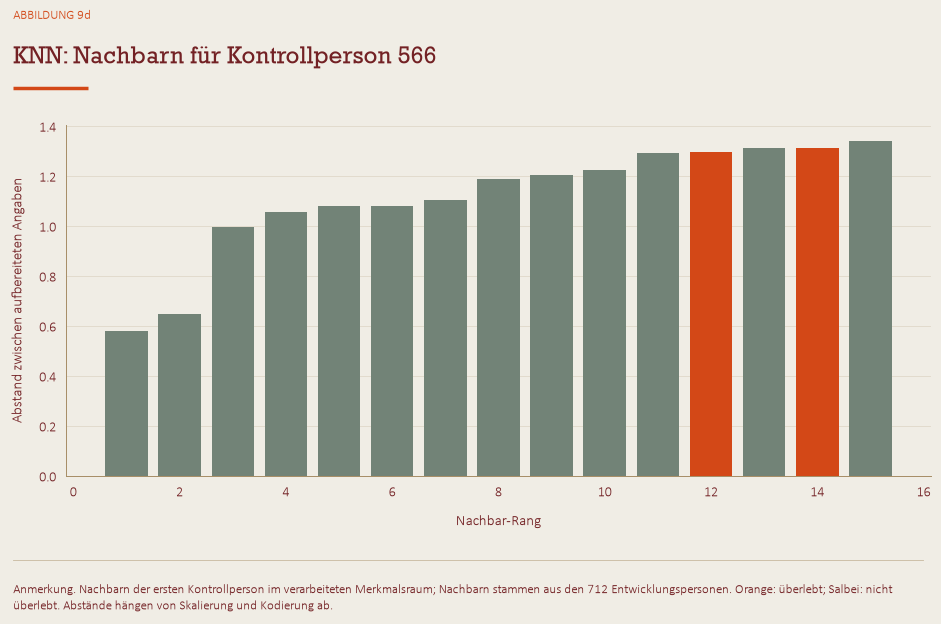

,Merkmal,Gewicht
0,Age,-0.3149
1,LogFahrpreisProPerson,0.4642
2,Pclass_1,0.4580
3,Pclass_2,0.0647
4,Pclass_3,-0.5135
5,Sex_female,0.6400
6,Sex_male,-0.6308
7,Embarked_C,0.0515
8,Embarked_Q,0.1932
9,Embarked_S,-0.2620


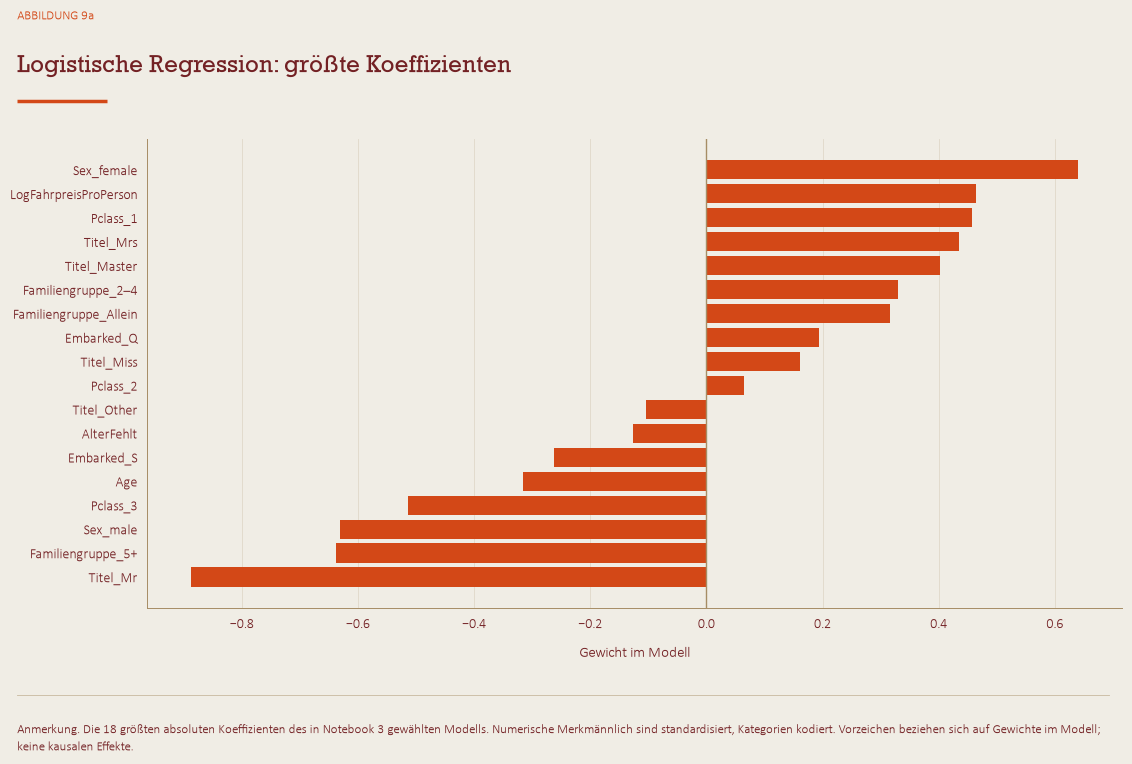

,Merkmal,Merkmalsbedeutung
5,Sex_male,0.4368
8,Pclass_3,0.1436
0,Age,0.1247
3,Fare,0.1158
26,Kabinenposition_Unklar,0.0830
14,Familiengruppe_5+,0.0423
11,Embarked_S,0.0139
33,Kabinenlage_E-Front,0.0133
44,ErwachsenerKinderticket,0.0101
1,SibSp,0.0095


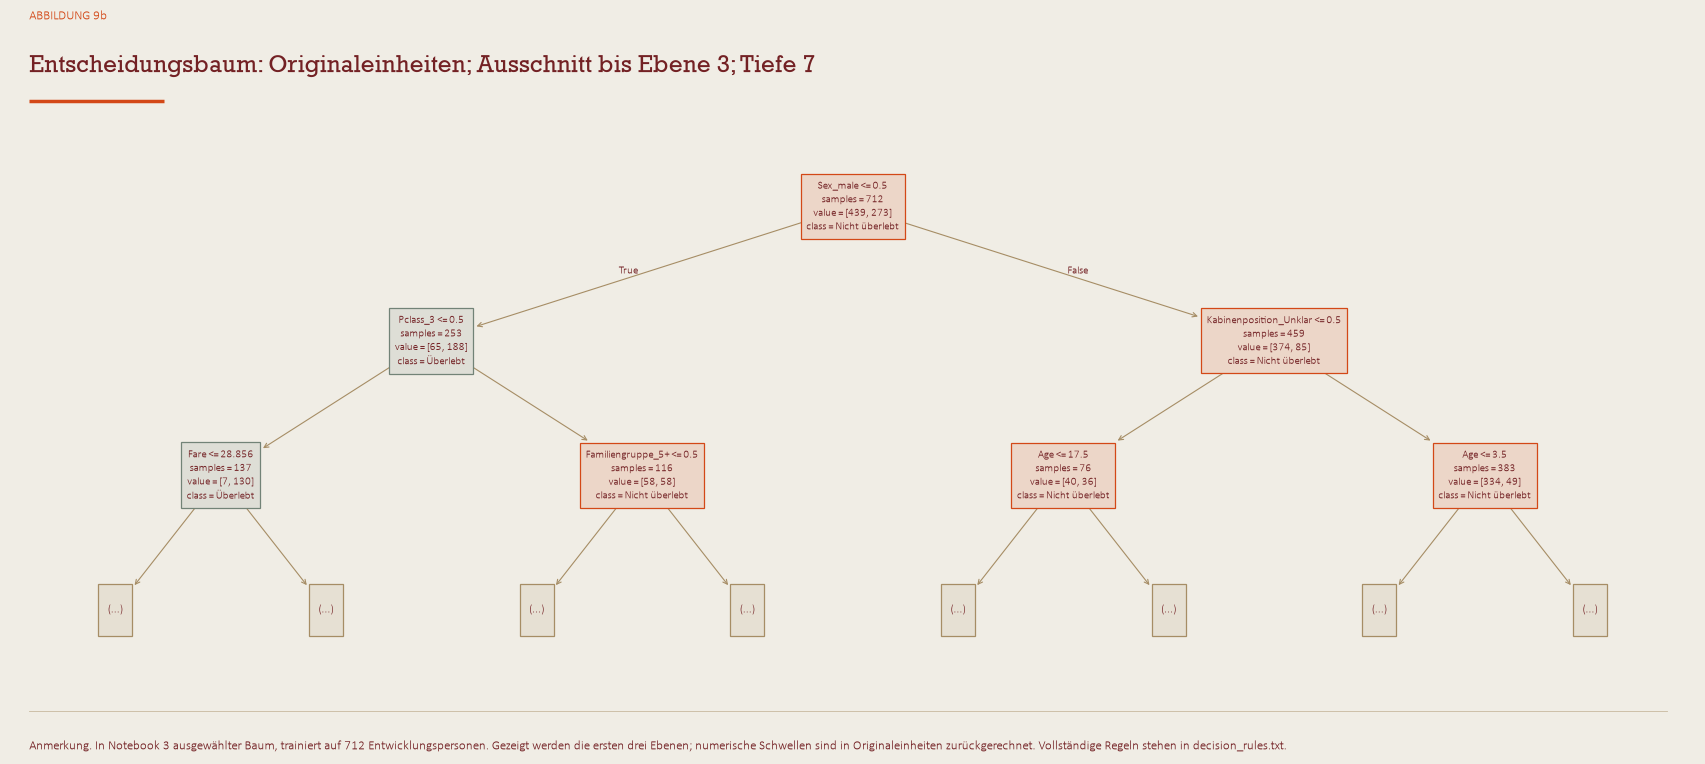

In [4]:
for family, model in modelle.items():
    estimator = model.named_steps['modell']
    names = model.named_steps['vorbereitung'].get_feature_names_out()
    if isinstance(estimator, LogisticRegression):
        table = pd.DataFrame({'Feature': names, 'Coefficient': estimator.coef_[0]})
        display(table)
        table.assign(Familie=family).to_csv(OUTPUT / 'logistic_coefficients.csv', index=False)
        plot = table.reindex(table.Coefficient.abs().sort_values(ascending=False).head(18).index).sort_values('Coefficient')
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.barh(plot.Feature, plot.Coefficient, color=COLORS['accent1'])
        ax.axvline(0, color=COLORS['accent2'], lw=1)
        ax.set(xlabel='Gewicht im Modell', title='Logistic Regression: größte Koeffizienten')
    elif isinstance(estimator, DecisionTreeClassifier):
        table = pd.DataFrame({'Feature': names, 'Feature importance': estimator.feature_importances_})
        display(table.sort_values('Feature importance', ascending=False))
        table.to_csv(OUTPUT / 'tree_importance.csv', index=False)
        raw_tree = deepcopy(estimator)
        prep = model.named_steps['vorbereitung']
        numeric_names = prep.transformers_[0][2]
        scaler = prep.named_transformers_['numerisch'].named_steps['skalieren']
        for node, feature_index in enumerate(raw_tree.tree_.feature):
            if feature_index >= 0 and names[feature_index] in numeric_names:
                j = numeric_names.index(names[feature_index])
                raw_tree.tree_.threshold[node] = raw_tree.tree_.threshold[node] * scaler.scale_[j] + scaler.mean_[j]
        (OUTPUT / 'decision_rules.txt').write_text(export_text(raw_tree, feature_names=list(names)), encoding='utf-8')
        fig, ax = plt.subplots(figsize=(18, 8))
        tree_annotations = plot_tree(raw_tree, feature_names=names, class_names=['Nicht überlebt', 'Überlebt'], max_depth=2, filled=False, impurity=False, fontsize=8, ax=ax)
        style_leaf_tree(tree_annotations)
        ax.set_title(f'Decision Tree: Originaleinheiten; Ausschnitt bis Ebene 3; Tiefe {estimator.get_depth()}')
    else:
        encoded = model.named_steps['vorbereitung'].transform(model.named_steps['ticketmerkmale'].transform(X_holdout))
        distances, neighbours = estimator.kneighbors(encoded[:1])
        neighbour_ids = entwicklung.iloc[neighbours[0]].PassengerId.to_numpy()
        table = pd.DataFrame({'PassengerId': neighbour_ids, 'Distance': distances[0], 'Survived': entwicklung.iloc[neighbours[0]].Survived.to_numpy()})
        display(table)
        table.to_csv(OUTPUT / 'knn_example_neighbours.csv', index=False)
        fig, ax = plt.subplots(figsize=(10, 6.5))
        ax.bar(range(1, len(table) + 1), table.Distance, color=[COLORS['accent1'] if v else COLORS['accent3'] for v in table.Survived])
        ax.set(xlabel='Nachbar-Rang', ylabel='Abstand zwischen aufbereiteten Angaben', title=f'KNN: Nachbarn für Kontrollperson {holdout.iloc[0].PassengerId}')
    filename = family.lower().replace(' ', '_') + '_erklaerung'
    title = ax.get_title()
    ax.set_title('')
    numbers = {'Logistic Regression': '9a', 'Decision Tree': '9b', 'KNN': '9d'}
    notes = {'Logistic Regression': 'Die 18 größten absoluten Koeffizienten des in Notebook 3 gewählten Modells. Numerische Merkmale sind standardisiert, Kategorien kodiert. Vorzeichen beziehen sich auf Log-Odds; keine kausalen Effekte.', 'Decision Tree': 'In Notebook 3 ausgewählter Baum, trainiert auf 712 Entwicklungspersonen. Gezeigt werden die ersten drei Ebenen; numerische Schwellen sind in Originaleinheiten zurückgerechnet. Vollständige Regeln stehen in decision_rules.txt.', 'KNN': 'Nachbarn der ersten Kontrollperson im verarbeiteten Merkmalsraum; Nachbarn stammen aus den 712 Entwicklungspersonen. Orange: überlebt; Salbei: nicht überlebt. Abstände hängen von Skalierung und Kodierung ab.'}
    save_leaf_figure(fig, numbers[family], title, notes[family], FIGURES / filename)



## Der vollständige Entscheidungsbaum

Der Ausschnitt oben zeigt die ersten Entscheidungen. Die folgende Grafik zeigt alle Verzweigungen von links nach rechts. Sie kann für die Präsentation vergrößert werden.


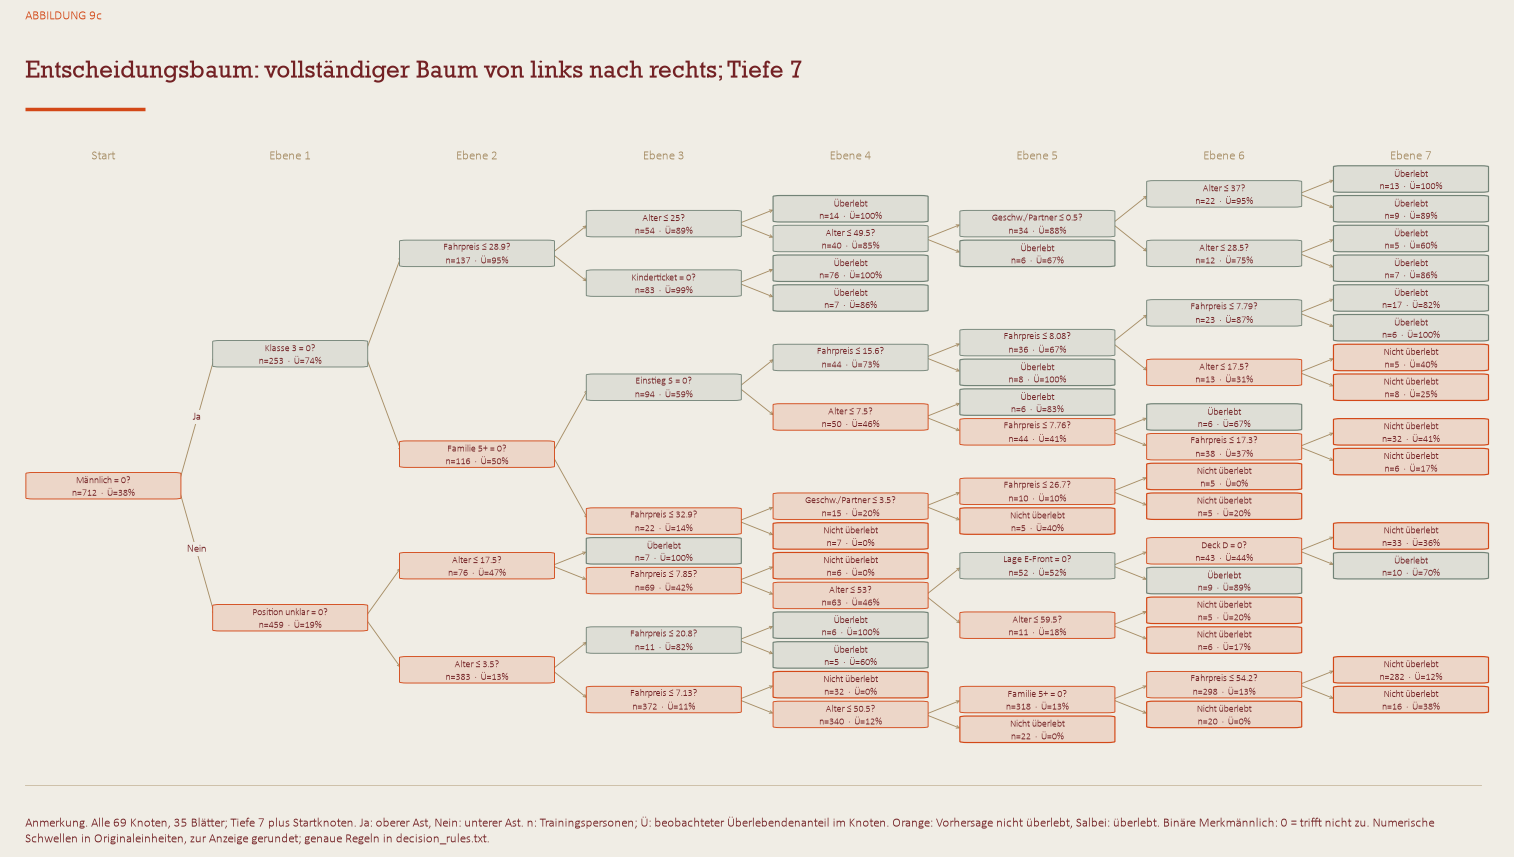

In [5]:
tree_model = modelle['Decision Tree']
tree_estimator = tree_model.named_steps['modell']
tree_names = tree_model.named_steps['vorbereitung'].get_feature_names_out()
display_tree = deepcopy(tree_estimator)
tree_prep = tree_model.named_steps['vorbereitung']
tree_numeric = tree_prep.transformers_[0][2]
tree_scaler = tree_prep.named_transformers_['numerisch'].named_steps['skalieren']
for node, feature_index in enumerate(display_tree.tree_.feature):
    if feature_index >= 0 and tree_names[feature_index] in tree_numeric:
        j = tree_numeric.index(tree_names[feature_index])
        display_tree.tree_.threshold[node] = display_tree.tree_.threshold[node] * tree_scaler.scale_[j] + tree_scaler.mean_[j]
fig, ax = plot_leaf_tree_horizontal(display_tree, tree_names)
save_leaf_figure(fig, '9c', f'Decision Tree: vollständiger Baum von links nach rechts; Tiefe {tree_estimator.get_depth()}', f'Alle {tree_estimator.tree_.node_count} Knoten, {tree_estimator.get_n_leaves()} Blätter; Tiefe {tree_estimator.get_depth()} plus Startknoten. Ja: oberer Ast, Nein: unterer Ast. n: Trainingspersonen; Ü: beobachteter Überlebendenanteil im Knoten. Orange: Vorhersage nicht überlebt, Salbei: überlebt. Binäre Merkmale: 0 = trifft nicht zu. Numerische Schwellen in Originaleinheiten, zur Anzeige gerundet; genaue Regeln in decision_rules.txt.', FIGURES / 'decision_tree_vollstaendig', dpi=600)



## Vergleich an den 179 Kontrollpersonen

Alle Modelle werden an denselben Personen geprüft. Der Anteil richtiger Vorhersagen heißt Genauigkeit. Weitere Kennzahlen zeigen, wie gut Überlebende erkannt werden und wie viele entsprechende Vorhersagen stimmen.

In der Fehlertabelle stehen richtige und falsche Zuordnungen nebeneinander. Die Kurven ergänzen den Vergleich der geschätzten Wahrscheinlichkeiten. Diese Kontrolle verändert die vorherige Modellwahl nicht.


,Genauigkeit,Anteil richtiger Überlebensvorhersagen,Anteil erkannter Überlebender,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Übereinstimmung über Zufallsniveau
Methode,,,,,,,
KNN,0.8324,0.8305,0.7101,0.7656,0.8472,0.1392,0.6364
Logistische Regression,0.8156,0.7903,0.7101,0.7481,0.8565,0.1377,0.6034
Entscheidungsbaum,0.7709,0.7917,0.5507,0.6496,0.8010,0.1674,0.4875
Frauenregel,0.7765,0.7377,0.6522,0.6923,0.7534,0.2235,0.5179
Mehrheitsregel,0.6145,0.0000,0.0000,0.0000,0.5000,0.2369,0.0000


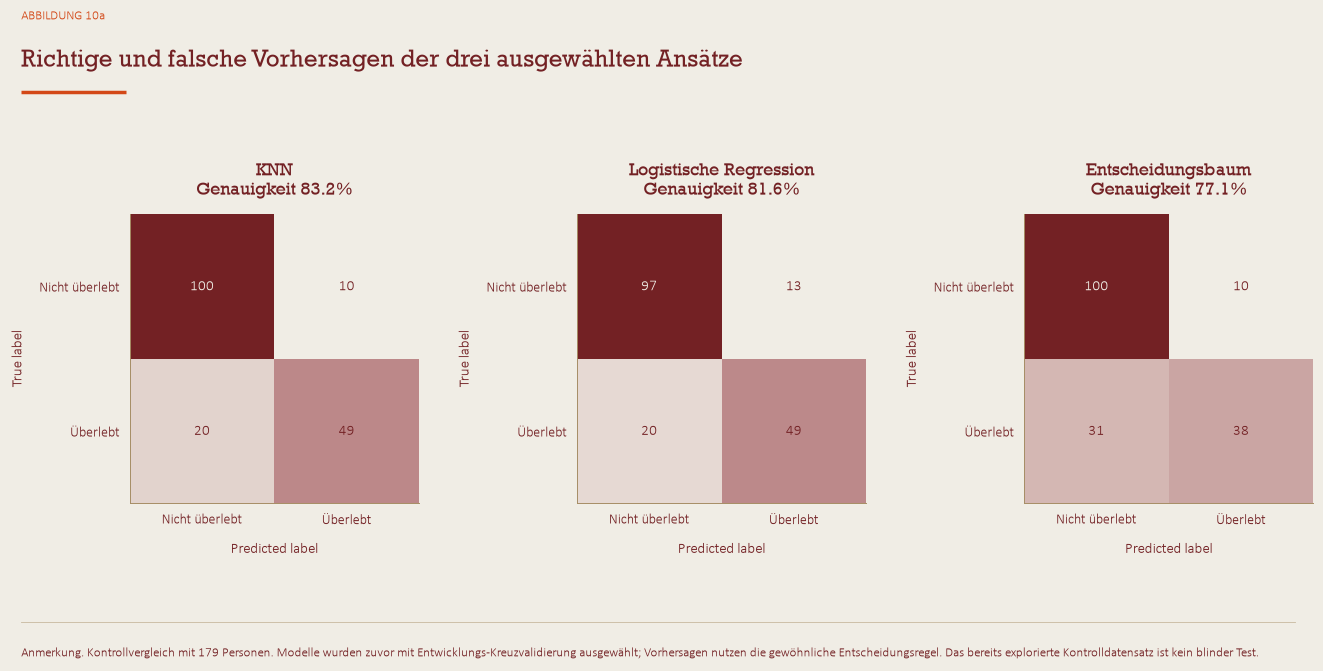

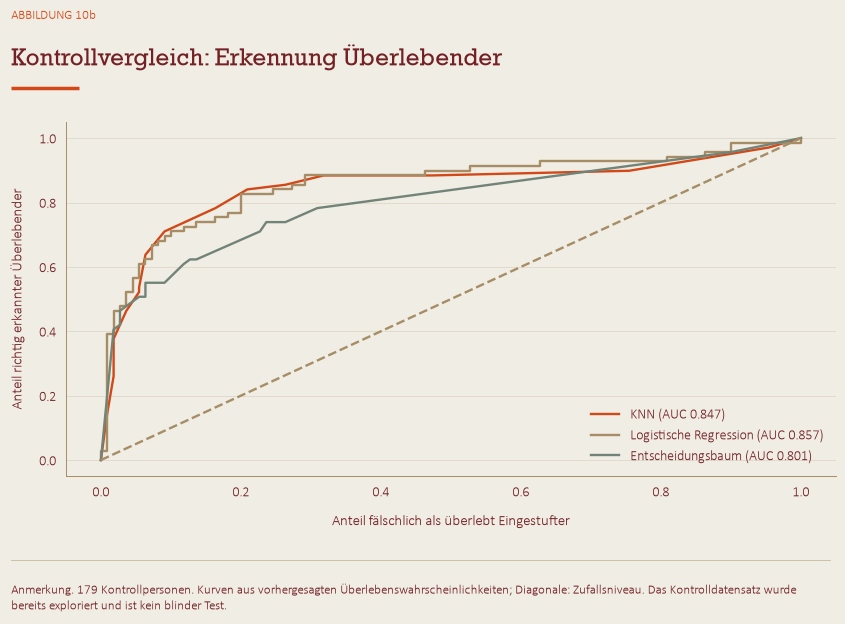

In [6]:
prognosen = {family: model.predict(X_holdout) for family, model in modelle.items()}
probabilities = {family: model.predict_proba(X_holdout)[:, 1] for family, model in modelle.items()}
prognosen['Frauenregel'] = X_holdout.Sex.eq('female').astype(int).to_numpy()
probabilities['Frauenregel'] = prognosen['Frauenregel'].astype(float)
prognosen['Mehrheitsregel'] = np.full(len(holdout), int(entwicklung.Survived.mode().iloc[0]))
probabilities['Mehrheitsregel'] = np.full(len(holdout), entwicklung.Survived.mean())
pruefwerte = pd.DataFrame([{'Methode': family, **metrics(wahrheit, prediction, probabilities[family])} for family, prediction in prognosen.items()]).set_index('Methode')
display(pruefwerte)
pruefwerte.to_csv(ERGEBNISSE / 'pruefset_vergleich.csv')
fig, axes = plt.subplots(1, 3, figsize=(14, 7))
for (family, model), ax in zip(modelle.items(), axes):
    ConfusionMatrixDisplay(confusion_matrix(wahrheit, prognosen[family]), display_labels=['Nicht überlebt', 'Überlebt']).plot(ax=ax, colorbar=False, cmap=LEAF_CMAP)
    ax.set_title(f"{BEZEICHNUNGEN.get(family, family)}\nAccuracy {pruefwerte.loc[family, 'Accuracy']:.1%}")
save_leaf_figure(fig, '10a', 'Confusion Matrices der drei ausgewählten Ansätze', 'Bekanntes Holdout mit 179 Personen. Modelle wurden zuvor mit Entwicklungs-CV ausgewählt; Vorhersagen nutzen die Standardentscheidung. Das bereits explorierte Holdout ist kein blinder Test.', FIGURES / 'confusion_matrices')
fig, ax = plt.subplots(figsize=(9, 6.5))
for family in modelle:
    fpr, tpr, _ = roc_curve(wahrheit, probabilities[family])
    ax.plot(fpr, tpr, label=f"{BEZEICHNUNGEN.get(family, family)} (AUC {pruefwerte.loc[family, 'ROC AUC']:.3f})")
ax.plot([0, 1], [0, 1], '--', color=COLORS['accent2'])
ax.set(xlabel='Anteil fälschlich als überlebt Eingestufter', ylabel='Anteil richtig erkannter Überlebender', title='Kontrollvergleich: Erkennung Überlebender')
ax.legend(loc='lower right')
ax.set_title('')
save_leaf_figure(fig, '10b', 'Kontrollvergleich: Erkennung Überlebender', '179 Kontrollpersonen. Kurven aus vorhergesagten Überlebenswahrscheinlichkeiten; Diagonale: Zufallsniveau. Das Holdout wurde bereits exploriert und ist kein blinder Test.', FIGURES / 'roc_curves')



## Wie reagieren die Modelle auf das Alter?

Wir verändern bei erfundenen Beispielpersonen nur das Alter von 18 bis 80 Jahren. Ticketklasse und Geschlecht werden getrennt betrachtet; die übrigen Angaben bleiben gleich.

Die Kurven zeigen das Verhalten der Modelle. Sie sind keine historischen Überlebensquoten und belegen keinen ursächlichen Alterseffekt.


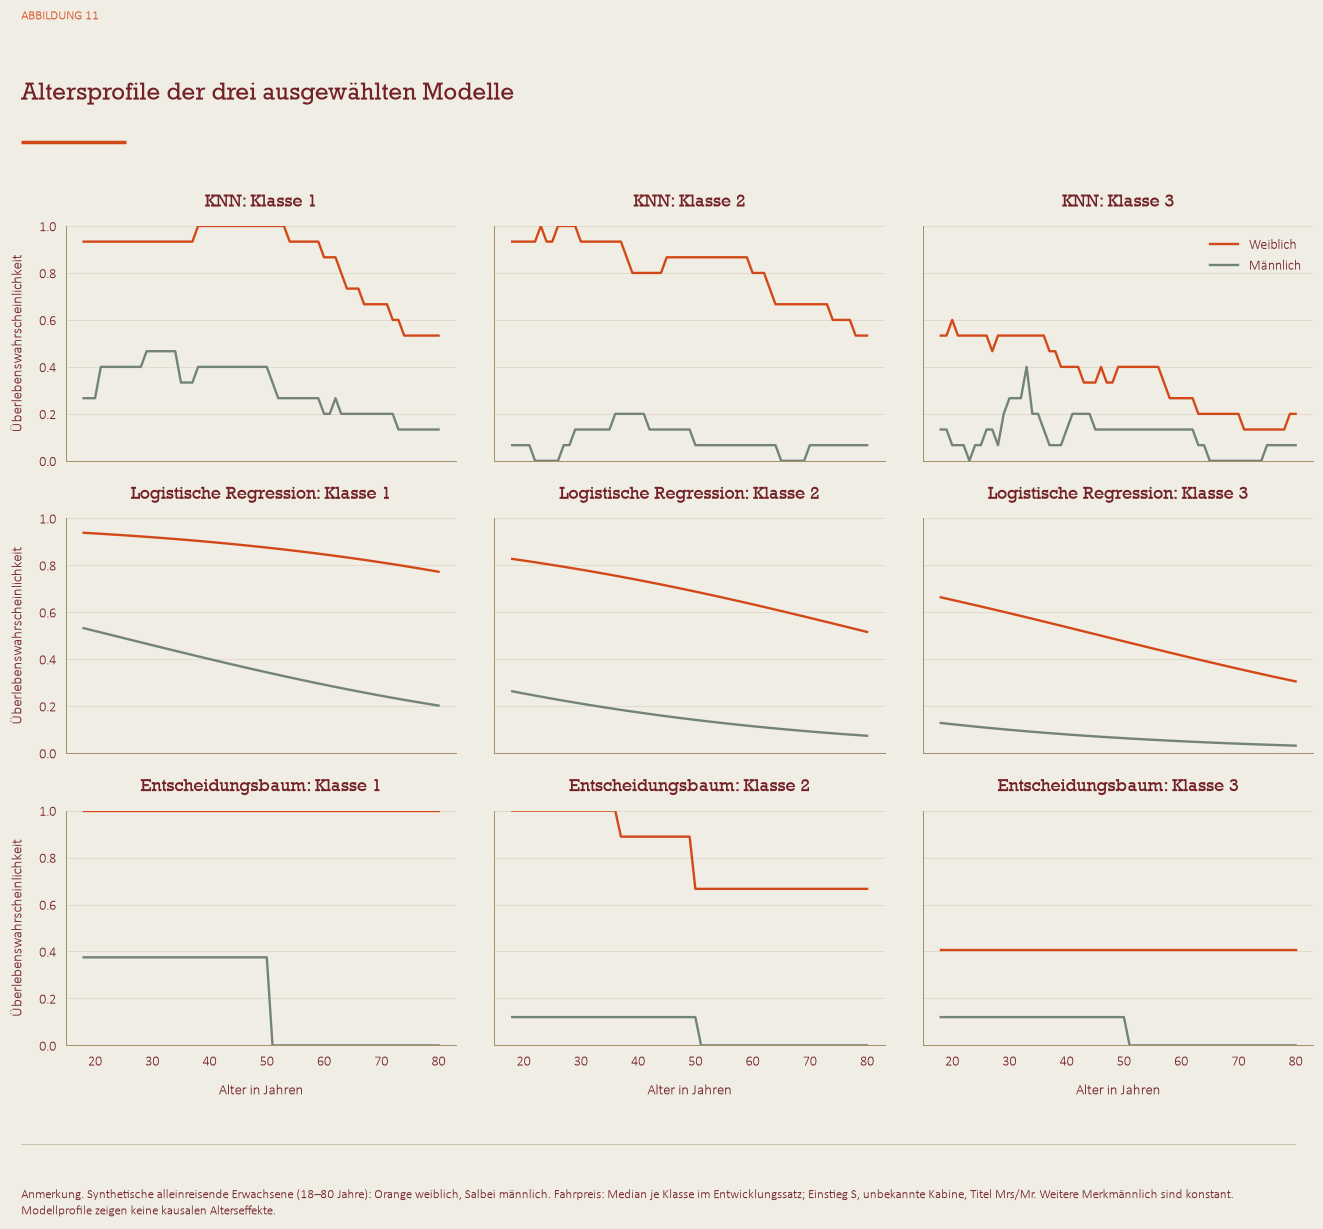

In [7]:
profilzeilen = []
fig, axes = plt.subplots(3, 3, figsize=(14, 13), sharex=True, sharey=True)
for model_index, (family, model) in enumerate(modelle.items()):
    for pclass in [1, 2, 3]:
        ax = axes[model_index, pclass - 1]
        for sex, title, color in [('female', 'Mrs', COLORS['accent1']), ('male', 'Mr', COLORS['accent3'])]:
            profile = pd.DataFrame({'PassengerId': -1, 'Age': np.arange(18, 81), 'Pclass': pclass, 'Sex': sex, 'SibSp': 0, 'Parch': 0, 'Fare': entwicklung.loc[entwicklung.Pclass.eq(pclass), 'Fare'].median(), 'Embarked': 'S', 'Ticket': '__SYNTHETIC_PROFILE__', 'Cabin': np.nan, 'Titel': title, 'EliteStatus': 0, 'HoherBerufsStatus': 0, 'AlterFehlt': 0, 'KabineFehlt': 1, 'EinstiegFehlt': 0, 'PreisFehlt': 0, 'Familiengruppe': 'Allein', 'Kabinendeck': 'Unbekannt', 'Kabinenposition': 'Unklar', 'Kabinenlage': 'Unbekannt'})
            probability = model.predict_proba(profile)[:, 1]
            profilzeilen.append(profile.assign(Methode=family, Wahrscheinlichkeit=probability))
            ax.plot(profile.Age, probability, color=color, label=BEZEICHNUNGEN.get(sex, sex))
        ax.set(title=f'{BEZEICHNUNGEN.get(family, family)}: Klasse {pclass}', ylim=(0, 1))
        ax.title.set_fontsize(10)
        if model_index == 2:
            ax.set_xlabel('Alter in Jahren')
        if pclass == 1:
            ax.set_ylabel('Überlebenswahrscheinlichkeit')
axes[0, 2].legend()
save_leaf_figure(fig, 11, 'Altersprofile der drei ausgewählten Modelle', 'Synthetische alleinreisende Erwachsene (18–80 Jahre): Orange weiblich, Salbei männlich. Fahrpreis: Median je Klasse im Entwicklungssatz; Einstieg S, unbekannte Kabine, Titel Mrs/Mr. Weitere Merkmale sind konstant. Modellprofile zeigen keine kausalen Alterseffekte.', FIGURES / 'altersprofile')



## Vorhersagen für die 418 Testpersonen

Die drei Modelle lernen nun mit allen Personen, deren Überleben bekannt ist. Danach erhält jede Testperson eine Vorhersage: 0 = nicht überlebt, 1 = überlebt.

`submission.csv` enthält die Vorhersagen des in Notebook 3 bestplatzierten Modells. Die drei Ansätze haben zusätzlich eigene Dateien. Die ausführliche Tabelle enthält Namen und geschätzte Wahrscheinlichkeiten.


In [8]:
slugs = {'Logistic Regression': 'logistic_regression', 'Decision Tree': 'decision_tree', 'KNN': 'knn'}
finale_modelle, submissions, passenger_tables = ({}, {}, [])
X_all = daten.drop(columns='Survived')
for family, development_model in modelle.items():
    model = clone(development_model).fit(X_all, daten.Survived)
    assert set(model.named_steps['ticketmerkmale'].fit_passenger_ids_) == set(daten.PassengerId)
    assert set(model.named_steps['ticketmerkmale'].fit_passenger_ids_).isdisjoint(test.PassengerId)
    prediction, probability = (model.predict(test).astype(int), model.predict_proba(test)[:, 1])
    submission = pd.DataFrame({'PassengerId': test.PassengerId, 'Survived': prediction})
    assert list(submission.columns) == ['PassengerId', 'Survived']
    assert len(submission) == 418 and submission.PassengerId.is_unique
    assert submission.PassengerId.equals(raw_test.PassengerId) and submission.Survived.isin([0, 1]).all()
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    submission.to_csv(f'submission_{slugs[family]}.csv', index=False)
    passengers = raw_test[['PassengerId', 'Name', 'Sex', 'Pclass', 'Age']].copy()
    passengers['Methode'], passengers['Überlebenswahrscheinlichkeit'], passengers['Vorhergesagtüberlebt'] = (family, probability, prediction)
    passenger_tables.append(passengers)
    finale_modelle[family], submissions[family] = (model, submission)
    print(deutsch(f'{BEZEICHNUNGEN.get(family, family)}: {prediction.sum()} von 418 als überlebt vorhergesagt ({prediction.mean():.1%}).'))
primary = top3[0]['Familie']
submissions[primary].to_csv('submission.csv', index=False)
pd.concat(passenger_tables, ignore_index=True).to_csv(ERGEBNISSE / 'passagier_vorhersagen.csv', index=False)
display(pd.concat(passenger_tables, ignore_index=True).head(10))
print(deutsch(f'submission.csv: {BEZEICHNUNGEN.get(primary, primary)}, gewählt vor der Holdout-Auswertung. Kaggle-Score noch unbekannt.'))



KNN: 156 von 418 als überlebt vorhergesagt (37.3%).
Logistische Regression: 168 von 418 als überlebt vorhergesagt (40.2%).
Entscheidungsbaum: 137 von 418 als überlebt vorhergesagt (32.8%).


,PassengerId,Name,Sex,Pclass,Age,Methode,Überlebenswahrscheinlichkeit,Vorhergesagtüberlebt
0,892,"Kelly, Mr. James",Männlich,3,34.5,KNN,0.0667,0
1,893,"Wilkes, Mrs. James (Ellen Needs)",Weiblich,3,47.0,KNN,0.3333,0
2,894,"Myles, Mr. Thomas Francis",Männlich,2,62.0,KNN,0.0667,0
3,895,"Wirz, Mr. Albert",Männlich,3,27.0,KNN,0.2000,0
4,896,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",Weiblich,3,22.0,KNN,0.6000,1
5,897,"Svensson, Mr. Johan Cervin",Männlich,3,14.0,KNN,0.1333,0
6,898,"Connolly, Miss. Kate",Weiblich,3,30.0,KNN,0.6667,1
7,899,"Caldwell, Mr. Albert Francis",Männlich,2,26.0,KNN,0.0667,0
8,900,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",Weiblich,3,18.0,KNN,0.7333,1
9,901,"Davies, Mr. John Samuel",Männlich,3,21.0,KNN,0.1333,0


submission.csv: KNN, gewählt vor der Kontrolldatensatz-Auswertung. Kaggle-Score noch unbekannt.


## Was bedeuten die Ergebnisse?

Die Modellwahl, die zusätzliche Prüfung der Auswahl und der Kontrollvergleich beantworten unterschiedliche Fragen. Kleine Unterschiede können von der Datenaufteilung abhängen.

Die Prüfung mit getrennten Tickets zeigt, wie gut die Vorhersage für unbekannte Reisegruppen funktioniert. Mehr Angaben verbessern ein Modell nicht automatisch. Besonders kleine Titelgruppen und die vereinfachte Kabinenlage bleiben unsichere Hinweise.

Für die Testpersonen kennen wir das tatsächliche Überleben nicht. Ein neuer Kaggle-Wert ist daher noch unbekannt.


In [9]:
summary = pd.DataFrame(top3)[['Gewinner-Rank', 'Familie', 'Modell', 'Merkmalsgruppe', 'CV-Accuracy', 'Fold-SD']]
summary = summary.merge(pruefwerte.reset_index()[['Methode', 'Accuracy', 'F1', 'ROC AUC', 'Brier score']], left_on='Familie', right_on='Methode').drop(columns='Methode')
summary = summary.rename(columns={'Accuracy': 'Known holdout Accuracy'})
for kind, label in [('Personen', 'Nested Personen Accuracy'), ('Ticketgruppen', 'Nested Ticketgruppen Accuracy')]:
    values = nested[nested.Bewertung.eq(kind)].set_index('Methode').Accuracy
    summary[label] = summary.Familie.map(values)
summary.to_csv(OUTPUT / 'ergebnisuebersicht.csv', index=False)
display(summary)



,Gewinner-Rank,Familie,Modell,Merkmalsgruppe,Mittlere Prüfgenauigkeit,Streuung der Prüfergebnisse,Genauigkeit im Kontrollvergleich,F1-Wert,Fläche unter der Prüfkurve,Wahrscheinlichkeitsfehler,Zusätzliche Prüfgenauigkeit (Personen),Zusätzliche Prüfgenauigkeit (Ticketgruppen)
0,1,KNN,KNN,Titel + Familie + Logpreis,0.8300,0.0320,0.8324,0.7656,0.8472,0.1392,0.8174,0.8202
1,2,Logistische Regression,Logistische Regression,Titel + Familie + Logpreis,0.8287,0.0245,0.8156,0.7481,0.8565,0.1377,0.8188,0.8146
2,3,Entscheidungsbaum,Erweiterter Entscheidungsbaum,Alle entwickelten Merkmale,0.8245,0.0204,0.7709,0.6496,0.8010,0.1674,0.8034,0.8062


In [10]:
row_lr = summary.loc[summary.Familie.eq('Logistic Regression')].iloc[0]
row_knn = summary.loc[summary.Familie.eq('KNN')].iloc[0]
differenz = 100 * abs(row_lr['Nested Personen Accuracy'] - row_knn['Nested Personen Accuracy'])
display(Markdown(f"**Ergebnis:** KNN und logistische Regression liegen in der zusätzlichen Personenprüfung nur **{differenz:.2f} Prozentpunkte** auseinander. Daraus ergibt sich kein klarer Vorteil eines Ansatzes. Die Auswahl aus Notebook 3 bleibt bestehen."))




**Ergebnis:** KNN und logistische Regression liegen in der zusätzlichen Personenprüfung nur **0.14 Prozentpunkte** auseinander. Daraus ergibt sich kein klarer Vorteil eines Ansatzes. Die Auswahl aus Notebook 3 bleibt bestehen.

## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.
